# Aim 2 model: internal well controls (simulation)

**Idea.** Every well holds several cell types (Parse) or cell lines (Tahoe). The well's technical effect lands on all of them, but a perturbation acts only on some of them. The cell types that do not respond are therefore internal controls for their own well.

**Model.** For donor (or plate) $d$, well $k$, cell type $c$:

$$y_{dkc} = \mu_{dc} + \tau_{kc} + z_{dk}^\top L_c + e_{dkc}$$

* $z_{dk}$: the well's technical state (low rank, shared by all cell types in the well). It contains a part that is identical on every donor plate (row, column, well-specific signature), which is why donors cannot remove it.
* $L_c$: cell-type-specific loadings (the feasibility tests showed the shared effect differs in size between cell types).
* $\tau_{kc}$: the response; zero for non-responding cell types.

**Estimation.** Fit $z$ and $L$ only on (well, cell type) entries that do not respond, then subtract $z_{dk}^\top L_c$ from every cell type in the well, including the responders. The response is the corrected well minus the corrected PBS wells. Which cell types respond is not known: the method starts by assuming nothing responds, calls responders on the corrected data against a PBS-vs-PBS null, and refits. A well in which every cell type responds has no internal control; the method flags it instead of correcting it.

**Why a simulation first.** Only here is the true response known. The simulator copies what the feasibility tests found in Parse and Tahoe: a shared well effect with cell-type-specific size (about 40% of the well effect), a part that recurs on every donor plate, all PBS wells in row H, and inert perturbations.

**Methods compared**

| Method | What it does |
|---|---|
| naive | well minus PBS wells (what the original analyses do) |
| row/col | removes row and column means (B-score-like) |
| RUVg | removes factors estimated from empirical control genes, per cell type |
| shared (ours) | internal well controls, responders discovered from the data |
| oracle | the true shared well effect removed (upper bound) |

**Scores.** For each method, a (well, cell type) pair is called responsive when its donor-replicated score is above the 95th percentile of PBS-vs-PBS scores of the same method. FPR: inert pairs called responsive. TPR: true responders called. Error: relative error of the estimated response for true responders.

All outputs go to `results/cache/aim2_model_simulation/`.

In [2]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

OUT_DIR = "results/cache/aim2_model_simulation"
os.makedirs(OUT_DIR, exist_ok=True)

ROWS = "ABCDEFGH"
WELLS = [r + str(c) for r in ROWS for c in range(1, 13)]
PBS = ["H7", "H8", "H9", "H10", "H11", "H12"]   # Parse layout: all controls in row H

N_SEEDS = 5                                   # replicate simulations per setting
P_RESP_GRID = [0.1, 0.3, 0.5, 0.7, 0.9]       # share of cell types that respond to an active perturbation
SHARED_GRID = [0.1, 0.2, 0.4, 0.6, 0.8]       # share of the well effect that is shared across cell types
OBSERVED_SHARED = (0.27, 0.68)                # Test D R2 range in Parse; Tahoe median 0.40

## 1. Simulator
12 donors × 96 wells × 6 cell types × 500 genes, fixed layout (each perturbation in the same well for every donor), PBS in H7 to H12. Defaults: 30% of cell types respond to an active perturbation, 15% of perturbations are inert, shared fraction 0.4.

In [3]:
def simulate(seed=0, D=12, C=6, G=500, R=3, p_resp=0.3, frac_inert=0.15,
             shared_frac=0.4, row_h=1.0, well_specific=0.7, well_sd=0.25, noise_sd=0.15,
             resp_size=0.5, resp_gene_frac=0.2):
    """Plate screen with a fixed layout. Returns dict with Y [D,K,C,G] and the truth."""
    rng = np.random.default_rng(seed)
    K = len(WELLS)
    is_pbs = np.array([w in PBS for w in WELLS])
    row = np.array([ROWS.index(w[0]) for w in WELLS])
    col = np.array([int(w[1:]) - 1 for w in WELLS])

    # well technical state: spatial part (same well on every donor plate) + donor-specific part
    row_eff = rng.normal(0, 0.5, (8, R)); row_eff[7] += row_h * rng.normal(0, 1, R)
    col_eff = rng.normal(0, 0.3, (12, R))
    # well-specific signature (position, barcode, reagent) that recurs on every donor plate
    spatial = row_eff[row] + col_eff[col] + rng.normal(0, well_specific, (K, R))
    z = spatial[None] + rng.normal(0, 0.7, (D, K, R))

    # loadings: shared gene programs, scaled per cell type, plus a cell-type-specific part
    V = rng.normal(0, 1, (R, G)) / np.sqrt(R)
    a = rng.uniform(0.5, 1.5, C)
    L = a[:, None, None] * V[None] + 0.3 * rng.normal(0, 1, (C, R, G)) / np.sqrt(R)
    W_shared = np.einsum("dkr,crg->dkcg", z, L)
    W_shared *= well_sd / W_shared.std()
    # unshared well effect, sized so the shared part is shared_frac of the well-effect variance
    s_un = well_sd * np.sqrt((1 - shared_frac) / shared_frac)
    W_un = rng.normal(0, s_un, (D, K, C, G))

    # responses: each non-PBS, non-inert perturbation hits a random subset of cell types
    resp = np.zeros((K, C), bool)
    active = (~is_pbs) & (rng.random(K) > frac_inert)
    resp[active] = rng.random((active.sum(), C)) < p_resp
    tau = np.zeros((K, C, G))
    for k in np.where(resp.any(1))[0]:
        prog = (rng.random(G) < resp_gene_frac) * rng.normal(0, 1, G)
        for c in np.where(resp[k])[0]:
            tau[k, c] = resp_size * rng.uniform(0.5, 1.5) * prog * (1 + 0.3 * rng.normal(0, 1, G))

    mu = rng.normal(0, 1, (1, 1, C, G)) + rng.normal(0, 0.3, (D, 1, C, G))
    Y = mu + tau[None] + W_shared + W_un + rng.normal(0, noise_sd, (D, K, C, G))
    return dict(Y=Y.astype(np.float32), W_shared=W_shared.astype(np.float32), tau=tau, resp=resp, is_pbs=is_pbs, row=row, col=col,
                inert=(~is_pbs) & (~resp.any(1)))

## 2. Methods
Each method returns the corrected data, from which the response is the corrected well minus the corrected PBS wells.

In [4]:
# ---------------- methods: each returns corrected Y1 [D,K,C,G] ----------------

def m_oracle(Y, W_shared, **kw):
    """Upper bound: the true shared well effect is removed."""
    return Y - W_shared


def m_naive(Y, is_pbs, **kw):
    return Y


def m_rowcol(Y, row, col, **kw):
    """B-score-like: remove row and column means per donor, cell type and gene."""
    Y1 = Y.copy()
    for r in range(8):
        Y1[:, row == r] -= Y[:, row == r].mean(1, keepdims=True)
    Y2 = Y1.copy()
    for c in range(12):
        Y2[:, col == c] -= Y1[:, col == c].mean(1, keepdims=True)
    return Y2


def m_ruvg(Y, R=3, ctrl_frac=0.1, **kw):
    """RUVg per cell type with empirical control genes (lowest variance across wells)."""
    D, K, C, G = Y.shape
    Y1 = np.empty_like(Y)
    for c in range(C):
        X = Y[:, :, c].reshape(D * K, G)
        X0 = X - X.reshape(D, K, G).mean(1, keepdims=True).repeat(K, 1).reshape(D * K, G)
        ctrl = np.argsort(X0.var(0))[: int(ctrl_frac * G)]
        U, s, _ = np.linalg.svd(X0[:, ctrl], full_matrices=False)
        F = U[:, :R]
        Y1[:, :, c] = (X0 - F @ (F.T @ X0)).reshape(D, K, G)
    return Y1


def fit_shared(Y0, nr, R=3, n_iter=30, ridge=1e-3):
    """Shared-well factor model on non-responding entries.
    Y0 [U,C,G] centred; nr [U,C] True where the cell type is a non-responder in that unit.
    W[u,c,:] = z[u] @ L[c]. Returns z [U,R], L [C,R,G], identifiable [U]."""
    U, C, G = Y0.shape
    full = nr.all(1)
    base = Y0[full] if full.sum() > R * 3 else Y0
    _, _, Vt = np.linalg.svd(base.reshape(len(base), C * G), full_matrices=False)
    L = Vt[:R].reshape(R, C, G).transpose(1, 0, 2).copy()
    for _ in range(n_iter):
        Gm = np.einsum("crg,csg->crs", L, L)                     # [C,R,R]
        b = np.einsum("crg,ucg->ucr", L, Y0)                       # [U,C,R]
        A = np.einsum("uc,crs->urs", nr.astype(float), Gm) + ridge * np.eye(R)
        rhs = np.einsum("uc,ucr->ur", nr.astype(float), b)
        z = np.linalg.solve(A, rhs[..., None])[..., 0]
        for c in range(C):
            m = nr[:, c]
            L[c] = np.linalg.lstsq(z[m], Y0[m, c], rcond=None)[0]
    return z, L, nr.any(1)


def m_shared(Y, nr_kc, R=3, **kw):
    """Internal well controls: estimate the well's technical state from its non-responding
    cell types, then remove its predicted effect from every cell type in the well."""
    D, K, C, G = Y.shape
    nr = np.broadcast_to(nr_kc[None], (D, K, C)).reshape(D * K, C)
    Yr = Y.reshape(D * K, C, G)
    # centre per (donor, cell type) on non-responding wells
    Y0 = np.empty_like(Yr)
    for d in range(D):
        sl = slice(d * K, (d + 1) * K)
        for c in range(C):
            m = nr[sl, c]
            Y0[sl, c] = Yr[sl, c] - Yr[sl, c][m].mean(0)
    z, L, ident = fit_shared(Y0, nr, R=R)
    W = np.einsum("ur,crg->ucg", z, L)
    return (Y0 - W).reshape(D, K, C, G), ident.reshape(D, K)

## 3. Scores, calls and discovery of responders

In [5]:
# ---------------- contrasts, scores, calls ----------------

def contrast(Y1, is_pbs):
    """Per-donor contrast of each well against the mean of the PBS wells."""
    return Y1 - Y1[:, is_pbs].mean(1, keepdims=True)


def score(diff):
    """diff [D,...,G]: mean over genes of squared t across donors."""
    D = diff.shape[0]
    m, s = diff.mean(0), diff.std(0, ddof=1) + 1e-6
    return ((m / (s / np.sqrt(D))) ** 2).mean(-1)


def null_scores(Y1, is_pbs):
    P = np.where(is_pbs)[0]
    out = []
    for p in P:
        others = [q for q in P if q != p]
        diff = Y1[:, p] - Y1[:, others].mean(1)          # [D,C,G]
        out.append(score(diff))
    return np.concatenate(out)


def evaluate(Y1, sim, q=0.95):
    is_pbs, tau, resp = sim["is_pbs"], sim["tau"], sim["resp"]
    diff = contrast(Y1, is_pbs)
    tau_hat = diff.mean(0)                                 # [K,C,G]
    sc = score(diff)                                       # [K,C]
    thr = np.quantile(null_scores(Y1, is_pbs), q)
    called = sc > thr
    tp = ~is_pbs
    null_pairs = tp[:, None] & ~resp
    err = np.linalg.norm(tau_hat - tau, axis=-1) / np.linalg.norm(tau, axis=-1).clip(1e-9)
    size = np.linalg.norm(tau_hat, axis=-1)
    return dict(
        fpr=called[null_pairs].mean(),
        tpr=called[resp].mean() if resp.any() else np.nan,
        rel_err=np.median(err[resp]) if resp.any() else np.nan,
        null_size=np.median(size[null_pairs]) / np.median(np.linalg.norm(tau[resp], axis=-1)),
        sc=sc, thr=thr)


def discover(Y, sim, R=3, n_rounds=3, q=0.95):
    """Start by assuming nothing responds; call responders on the corrected data; refit."""
    K, C = sim["resp"].shape
    nr = np.ones((K, C), bool)
    for _ in range(n_rounds):
        Y1, ident = m_shared(Y, nr, R=R)
        diff = contrast(Y1, sim["is_pbs"])
        sc = score(diff)
        thr = np.quantile(null_scores(Y1, sim["is_pbs"]), q)
        nr = sc <= thr
        nr[sim["is_pbs"]] = True
    Y1, ident = m_shared(Y, nr, R=R)
    return Y1, nr, ident

## 4. One example
Default setting, one seed. `mask accuracy`: share of (well, cell type) pairs whose responder status was recovered.

In [6]:
METHODS = ["naive", "row/col", "RUVg", "shared (ours)", "oracle"]

def run_all(sim):
    Y = sim["Y"]
    out = {}
    out["naive"] = evaluate(m_naive(Y, sim["is_pbs"]), sim)
    out["row/col"] = evaluate(m_rowcol(Y, sim["row"], sim["col"]), sim)
    out["RUVg"] = evaluate(m_ruvg(Y), sim)
    Y1, nr, ident = discover(Y, sim)
    out["shared (ours)"] = evaluate(Y1, sim)
    out["shared (ours)"]["mask_acc"] = (nr == ~sim["resp"]).mean()
    out["shared (ours)"]["flagged_wells"] = (~nr[~sim["is_pbs"]].any(1)).mean()
    out["oracle"] = evaluate(m_oracle(Y, sim["W_shared"]), sim)
    return out

t0 = time.time()
ex = run_all(simulate(0))
tab = pd.DataFrame({m: {k: v for k, v in ex[m].items() if k not in ("sc", "thr")} for m in METHODS}).T
print(tab.round(3).to_string())
print(f"{time.time() - t0:.0f}s")

                 fpr    tpr  rel_err  null_size  mask_acc  flagged_wells
naive          0.342  0.716    1.236      1.199       NaN            NaN
row/col        0.079  0.672    0.780      0.670       NaN            NaN
RUVg           0.389  0.993    0.683      0.615       NaN            NaN
shared (ours)  0.133  1.000    0.476      0.427     0.906          0.022
oracle         0.133  1.000    0.445      0.438       NaN            NaN
3s


## 5. Replicates and sweeps
Default setting over `N_SEEDS` seeds, then one parameter changed at a time. Cached in `sim_results.csv`; delete it to rerun.

In [7]:
CACHE = os.path.join(OUT_DIR, "sim_results.csv")
if os.path.exists(CACHE):
    res = pd.read_csv(CACHE)
    print("Loaded cache:", res.shape)
else:
    jobs = [("default", None, s, {}) for s in range(N_SEEDS)]
    jobs += [("p_resp", v, s, {"p_resp": v}) for v in P_RESP_GRID for s in range(N_SEEDS)]
    jobs += [("shared_frac", v, s, {"shared_frac": v}) for v in SHARED_GRID for s in range(N_SEEDS)]
    rows, t0 = [], time.time()
    for i, (sweep, val, seed, kw) in enumerate(jobs, 1):
        out = run_all(simulate(100 + seed, **kw))
        for m in METHODS:
            r = {k: v for k, v in out[m].items() if k not in ("sc", "thr")}
            rows.append(dict(sweep=sweep, value=val, seed=seed, method=m, **r))
        el = time.time() - t0
        print(f"  {i}/{len(jobs)} runs | elapsed {el / 60:.1f} min | remaining ~{el / i * (len(jobs) - i) / 60:.1f} min",
              flush=True)
    res = pd.DataFrame(rows)
    res.to_csv(CACHE, index=False)
    print("Saved:", CACHE)

summary = (res[res.sweep == "default"].groupby("method")[["fpr", "tpr", "rel_err", "null_size"]]
           .median().loc[METHODS])
print(summary.round(3).to_string())

Loaded cache: (275, 10)
                 fpr    tpr  rel_err  null_size
method                                         
naive          0.409  0.851    1.095      1.067
row/col        0.109  0.716    0.735      0.652
RUVg           0.315  0.993    0.679      0.623
shared (ours)  0.094  1.000    0.453      0.445
oracle         0.088  1.000    0.452      0.452


## 6. Figure
A: false and true calls in the default setting. B: response error. C: error as more cell types respond (fewer internal controls), with the share of wells the method flags as having no control. D: false calls against the shared fraction of the well effect; grey band: range observed in Parse and Tahoe.

/tmp/ipykernel_556010/981836060.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
/tmp/ipykernel_556010/981836060.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
/tmp/ipykernel_556010/981836060.py:58: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])


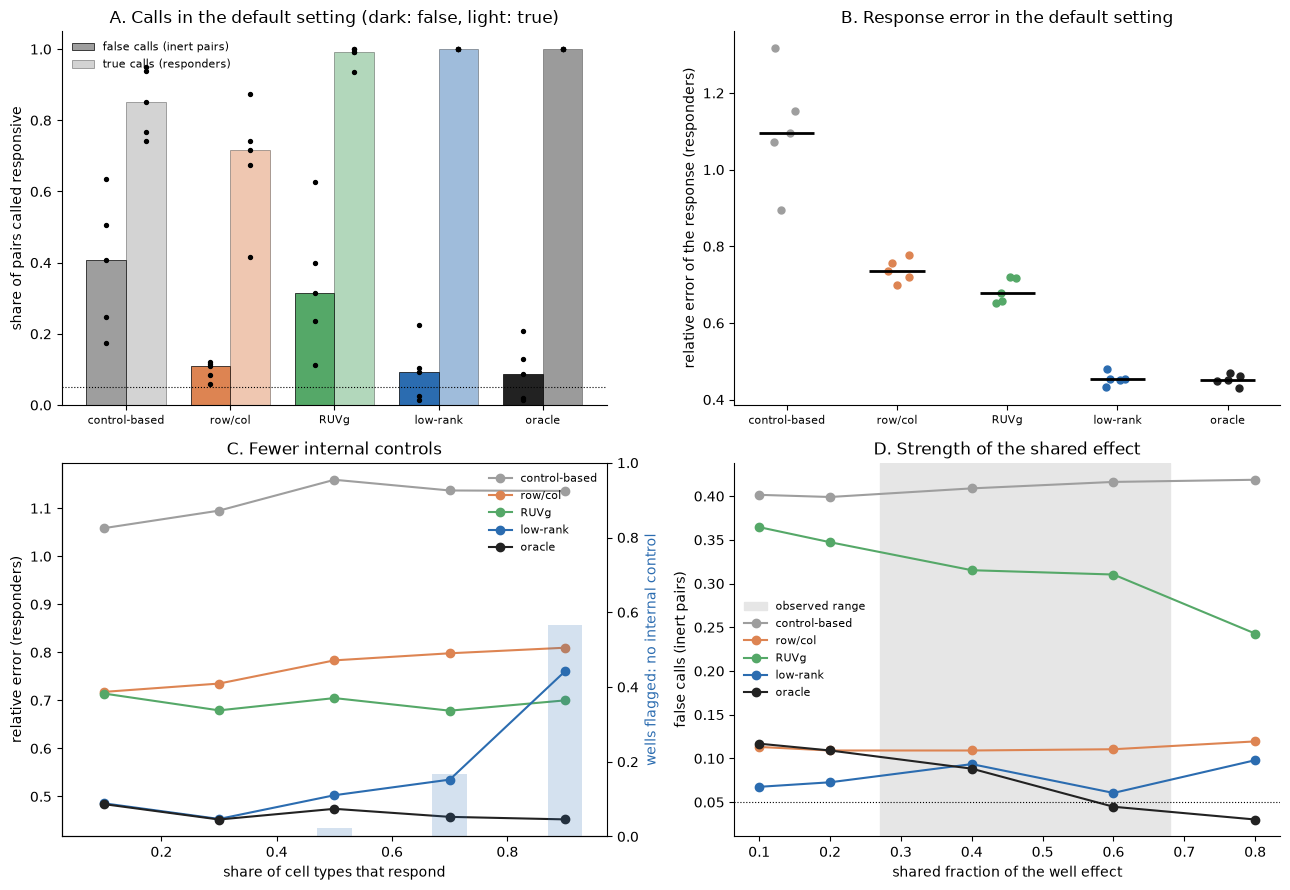

Saved: /home/w202gxg/multi-modal/Proposal3/results/cache/aim2_model_simulation/aim2_model_simulation.png True


In [8]:
COL = {"naive": "#9e9e9e", "row/col": "#dd8452", "RUVg": "#55a868", "shared (ours)": "#2b6cb0", "oracle": "#222222"}
dft = res[res.sweep == "default"]
fig, ax = plt.subplots(2, 2, figsize=(13, 9))

a = ax[0, 0]
x = np.arange(len(METHODS)); w = 0.38
for j, (met, lab, alpha) in enumerate([("fpr", "false calls (inert pairs)", 1.0), ("tpr", "true calls (responders)", 0.45)]):
    med = dft.groupby("method")[met].median().loc[METHODS]
    a.bar(x + (j - 0.5) * w, med.values, w, color=[COL[m] for m in METHODS], alpha=alpha, label=lab,
          edgecolor="k", linewidth=0.5)
    for i, m in enumerate(METHODS):
        v = dft[dft.method == m][met].values
        a.scatter(np.full(len(v), i + (j - 0.5) * w), v, s=8, color="k", zorder=3)
a.axhline(0.05, color="k", ls=":", lw=0.8)
a.set_xticks(x); a.set_xticklabels(METHODS, fontsize=8); a.set_ylim(0, 1.05)
a.set_ylabel("share of pairs called responsive"); a.legend(frameon=False, fontsize=8)
a.set_title("A. Calls in the default setting (dark: false, light: true)")

a = ax[0, 1]
for i, m in enumerate(METHODS):
    v = dft[dft.method == m].rel_err.values
    a.scatter(np.full(len(v), i) + np.random.default_rng(i).uniform(-.12, .12, len(v)), v, color=COL[m], s=25)
    a.hlines(np.median(v), i - .25, i + .25, color="k", lw=2)
a.set_xticks(x); a.set_xticklabels(METHODS, fontsize=8)
a.set_ylabel("relative error of the response (responders)")
a.set_title("B. Response error in the default setting")

a = ax[1, 0]
sw = res[res.sweep == "p_resp"]
for m in METHODS:
    med = sw[sw.method == m].groupby("value").rel_err.median()
    a.plot(med.index, med.values, "-o", color=COL[m], label=m)
fl = sw[sw.method == "shared (ours)"].groupby("value").flagged_wells.median()
a2 = a.twinx(); a2.bar(fl.index, fl.values, 0.06, color=COL["shared (ours)"], alpha=0.2)
a2.set_ylabel("wells flagged: no internal control", color=COL["shared (ours)"]); a2.set_ylim(0, 1)
a.set_xlabel("share of cell types that respond"); a.set_ylabel("relative error (responders)")
a.legend(frameon=False, fontsize=8); a.set_title("C. Fewer internal controls")

a = ax[1, 1]
sw = res[res.sweep == "shared_frac"]
a.axvspan(*OBSERVED_SHARED, color="0.9", zorder=0, label="observed range")
for m in METHODS:
    med = sw[sw.method == m].groupby("value").fpr.median()
    a.plot(med.index, med.values, "-o", color=COL[m], label=m)
a.axhline(0.05, color="k", ls=":", lw=0.8)
a.set_xlabel("shared fraction of the well effect"); a.set_ylabel("false calls (inert pairs)")
a.legend(frameon=False, fontsize=8); a.set_title("D. Strength of the shared effect")

for a in ax.ravel():
    a.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
png = os.path.abspath(os.path.join(OUT_DIR, "aim2_model_simulation.png"))
RENAME = {"naive": "control-based", "ours": "signature", "final": "signature",
          "final (v2)": "signature", "shared (ours)": "low-rank"}

def rename_labels(fig, mapping=RENAME):
    for a in fig.axes:
        a.set_xticklabels([mapping.get(t.get_text(), t.get_text()) for t in a.get_xticklabels()])
        leg = a.get_legend()
        if leg:
            for t in leg.get_texts():
                t.set_text(mapping.get(t.get_text(), t.get_text()))
        for t in a.texts:                       # point labels, e.g. in aim2_baselines.png
            t.set_text(mapping.get(t.get_text(), t.get_text()))

rename_labels(fig)
fig.savefig(png, dpi=200); fig.savefig(png.replace(".png", ".pdf"))
plt.show()
print("Saved:", png, os.path.exists(png))

## 7. Verdict

In [9]:
d = summary
obs = res[(res.sweep == "shared_frac") & res.value.between(*OBSERVED_SHARED)]
obs_fpr = obs.groupby("method").fpr.median()
verdict = pd.DataFrame([
    ("Naive analysis calls inert pairs responsive", f"{d.loc['naive', 'fpr']:.2f}", d.loc["naive", "fpr"] > 0.2),
    ("Ours: false calls (default)", f"{d.loc['shared (ours)', 'fpr']:.2f}", d.loc["shared (ours)", "fpr"] < 0.15),
    ("Ours keeps power (TPR)", f"{d.loc['shared (ours)', 'tpr']:.2f}", d.loc["shared (ours)", "tpr"] > 0.9),
    ("Ours: error vs oracle", f"{d.loc['shared (ours)', 'rel_err']:.2f} vs {d.loc['oracle', 'rel_err']:.2f}",
     d.loc["shared (ours)", "rel_err"] < 1.2 * d.loc["oracle", "rel_err"]),
    ("Ours beats every baseline on error", f"{d.loc['shared (ours)', 'rel_err']:.2f} vs best {d.loc[['naive', 'row/col', 'RUVg'], 'rel_err'].min():.2f}",
     d.loc["shared (ours)", "rel_err"] < d.loc[["naive", "row/col", "RUVg"], "rel_err"].min()),
    ("Ours: false calls in the observed shared range", f"{obs_fpr['shared (ours)']:.2f} (naive {obs_fpr['naive']:.2f})",
     obs_fpr["shared (ours)"] < obs_fpr["naive"]),
], columns=["check", "value", "passes"])
verdict.to_csv(os.path.join(OUT_DIR, "verdict.csv"), index=False)
print(verdict.to_string(index=False))

                                         check             value  passes
   Naive analysis calls inert pairs responsive              0.41    True
                   Ours: false calls (default)              0.09    True
                        Ours keeps power (TPR)              1.00    True
                         Ours: error vs oracle      0.45 vs 0.45    True
            Ours beats every baseline on error 0.45 vs best 0.68    True
Ours: false calls in the observed shared range 0.08 (naive 0.41)    True


## 8. Known limits of this first version
* Responders are called with a hard threshold. When the shared fraction is high, the PBS null becomes tight and some inert pairs are called responsive, which also removes internal controls. A spike-and-slab prior on the responder mask (with uncertainty) is the planned fix.
* The PBS null is estimated from only 6 wells per donor, so the 95th percentile is noisy (the oracle itself sits near 0.05 to 0.13).
* A well in which every cell type responds has no internal control. The method flags it; Aim 2 adds bounds for those wells instead of a point estimate.
* Next: run the same code on Parse (inert cytokines as ground-truth nulls) and on Tahoe (replicate plates 6 and 14 as ground truth).

In [10]:
for sweep, metric in [("p_resp", "rel_err"), ("shared_frac", "fpr")]:
    t = (res[res.sweep == sweep].groupby(["method", "value"])[metric].median()
         .unstack().loc[METHODS].round(2))
    print(sweep, metric); print(t.to_string()); print()
print("flagged:", res[(res.sweep == "p_resp") & (res.method == "shared (ours)")]
      .groupby("value").flagged_wells.median().round(2).to_dict())
print("oracle fpr range:", res[res.method == "oracle"].groupby(["sweep", "value"]).fpr.median().agg(["min", "max"]).round(2).to_dict())

p_resp rel_err
value           0.1   0.3   0.5   0.7   0.9
method                                     
naive          1.06  1.10  1.16  1.14  1.14
row/col        0.72  0.74  0.78  0.80  0.81
RUVg           0.71  0.68  0.70  0.68  0.70
shared (ours)  0.49  0.45  0.50  0.54  0.76
oracle         0.48  0.45  0.47  0.46  0.45

shared_frac fpr
value           0.1   0.2   0.4   0.6   0.8
method                                     
naive          0.40  0.40  0.41  0.42  0.42
row/col        0.11  0.11  0.11  0.11  0.12
RUVg           0.36  0.35  0.32  0.31  0.24
shared (ours)  0.07  0.07  0.09  0.06  0.10
oracle         0.12  0.11  0.09  0.04  0.03

flagged: {0.1: 0.0, 0.3: 0.0, 0.5: 0.02, 0.7: 0.17, 0.9: 0.57}
oracle fpr range: {'min': 0.03, 'max': 0.12}
